# Climbable-rock detection at Horseshoe Canyon Ranch — proof of concept

**Question:** can a PointNet++ pretrained on everyday objects (ModelNet40) be fine-tuned on airborne LiDAR so that, given a GPS location, it says whether the rock there is **climbable** — using only Mountain Project route locations as (weak) labels?

**Pipeline**

| step | module | what happens |
|---|---|---|
| 1 | `mountain_project.py` | one cached request to Mountain Project's route-finder CSV export → 530 routes on 33 wall pins |
| 2 | `usgs_ept.py` | stream USGS 3DEP LiDAR (Entwine Point Tiles on AWS) for the ranch bbox with PDAL, reproject to UTM 15N, cache |
| 3 | `labeling.py` | surface normals → steep, single-return "rock" points → snap each wall pin to its cliff line → one 2.5 m cylinder per route spanning the cliff base to base + route length → contextual + random negatives (mostly-cliff unknowns are ignored, not labelled 0) |
| 4 | `dataset.py` | 5 m-radius vertical point column per sample, 1024 points, unit-sphere normalised; **whole walls** go to train / val / test |
| 5 | `model.py`, `trainer.py` | PointNet++ SSG with ModelNet40 weights; compare *scratch* vs *frozen backbone* vs *full fine-tune* on held-out walls |
| 6 | `inference.py` | slide the model over the whole ranch → P(climbable) map |

**Labels are binary** (climbable = 1, not climbable = 0). Slab/face/overhang classification was dropped: Mountain Project has no wall-angle field and airborne LiDAR barely sees under roofs — section 4 measures how much of each route the LiDAR actually captures, which is the feasibility question behind the 4-class version.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from config import ExperimentConfig
from dataset import make_loaders, save_samples, split_summary, split_walls
from inference import plot_probability_map, predict_grid
from labeling import PointCloud, build_samples, compute_normals
from model import build_model, count_parameters
from mountain_project import filter_bbox, load_routes, walls_from_routes
from trainer import TrainConfig, compare_modes, pick_device
from usgs_ept import lonlat_to_work, load_region

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# On a laptop (no CUDA) run a fast end-to-end check; on the GPU machine train for real
FAST_DEV_RUN = not torch.cuda.is_available()
EPOCHS = 2 if FAST_DEV_RUN else 60
GRID_SPACING_M = 15.0 if FAST_DEV_RUN else 4.0
BATCH_SIZE = 16 if FAST_DEV_RUN else 32

cfg = ExperimentConfig()
print("device:", pick_device(), "| FAST_DEV_RUN:", FAST_DEV_RUN, "| epochs:", EPOCHS)
cfg

/Users/zachf/miniconda3/envs/final-proj-torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | FAST_DEV_RUN: True | epochs: 2


ExperimentConfig(region=RegionConfig(name='horseshoe_canyon_ranch', bbox_lonlat=(-93.2995, 35.9985, -93.2825, 36.0135), ept_name='AR_North_Corridor_2017', tile_size_m=250.0), label=LabelConfig(normal_k=12, normal_voxel_m=0.5, steep_slope_deg=60.0, steep_single_return_only=True, snap_search_radius_m=30.0, route_spacing_m=3.0, route_radius_m=2.5, min_steep_points=8, stepback_m=(12.0, 20.0), ignore_buffer_m=40.0, max_steep_fraction_random_neg=0.25, n_random_negatives=300, drop_default_pin_routes=True), patch=PatchConfig(radius_m=5.0, num_points=1024, min_points=64, normalize='unit_sphere', fixed_scale_m=15.0), split=SplitConfig(val_frac=0.2, test_frac=0.2, seed=42))

## 1. Known routes from Mountain Project

The route-finder export gives each route's **wall** coordinate, not the route's own — every route on a wall shares one pin. Routes whose pin is the ranch's own default pin (36.0118, −93.2922: Land of the Lost, Ren and Stimpy, Mullet Buttress) were never placed on a wall, so they are dropped.

In [2]:
routes = filter_bbox(load_routes(), cfg.region.bbox_lonlat)
walls = walls_from_routes(routes)
print(f"{len(routes)} routes on {len(walls)} wall pins; route types:")
print(routes["route_type"].value_counts().head(6).to_string())
walls

530 routes on 33 wall pins; route types:
route_type
Sport             406
Trad              117
Sport, TR           3
Trad, TR            2
Sport, Boulder      1
Trad, Sport         1


,wall,lat,lon,default_pin,n_routes,median_length_m,max_length_m
0,North Forty Routes,36.00881,-93.29549,False,142,13.7160,39.6240
1,The Far East,36.00423,-93.28429,False,35,16.7640,27.4320
2,Walls Of Moria,36.00196,-93.29396,False,25,16.7640,24.3840
3,Kindergarten Boulder,36.00878,-93.29377,False,23,10.6680,12.1920
4,Crackhouse Alley,35.99981,-93.29369,False,22,21.3360,21.3360
5,The Land Beyond Routes,36.00982,-93.29337,False,21,10.6680,13.7160
6,Land of the Lost,36.01180,-93.29220,True,20,11.5824,15.2400
7,Confederate Cracks,36.00132,-93.29346,False,20,19.8120,24.3840
8,The Arcade,36.00314,-93.29470,False,18,18.2880,21.3360
9,Rosie's Cantina Area,36.00644,-93.28695,False,18,13.7160,15.2400


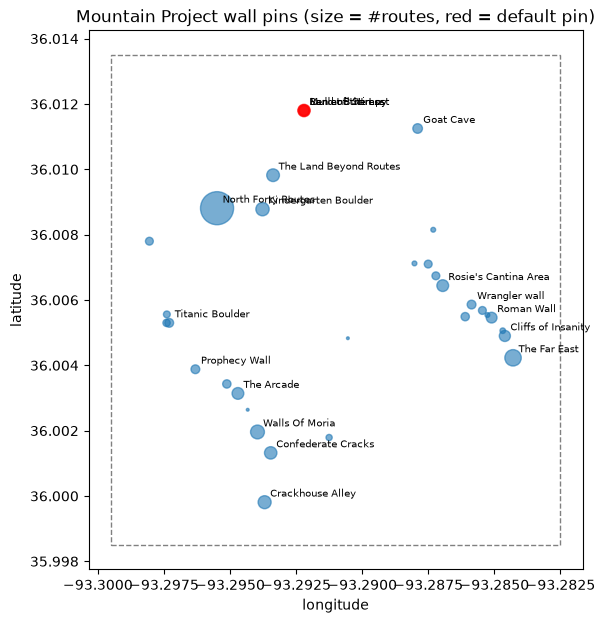

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))
min_lon, min_lat, max_lon, max_lat = cfg.region.bbox_lonlat
ax.add_patch(plt.Rectangle((min_lon, min_lat), max_lon - min_lon, max_lat - min_lat, fill=False, ls="--", color="gray"))
sc = ax.scatter(walls["lon"], walls["lat"], s=walls["n_routes"] * 4, c=walls["default_pin"].map({True: "red", False: "tab:blue"}), alpha=0.6)
for _, w in walls[walls["n_routes"] >= 10].iterrows():
    ax.annotate(w["wall"], (w["lon"], w["lat"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="longitude", ylabel="latitude", title="Mountain Project wall pins (size = #routes, red = default pin)", aspect=1 / np.cos(np.radians(36)))
plt.show()

## 2. USGS 3DEP LiDAR, streamed from Entwine Point Tiles

`readers.ept` downloads only the octree tiles that intersect each 250 m request square. The first run streams ~19 M points (a few minutes) and caches them in `data/`; later runs load the cache. Noise classes 7/18 are dropped and everything is reprojected from Web Mercator (whose metres are 24 % too long at 36° N) to UTM 15N.

In [4]:
cloud = load_region(cfg.region)
xyz = cloud["xyz"]
extent = xyz[:, :2].max(0) - xyz[:, :2].min(0)
print(f"{len(xyz):,} points over {extent[0]:.0f} m x {extent[1]:.0f} m "
      f"-> {len(xyz) / extent.prod():.1f} pts/m^2; elevation {xyz[:, 2].min():.0f}-{xyz[:, 2].max():.0f} m")
print("classification counts:", dict(zip(*np.unique(cloud["classification"], return_counts=True))))
print("returns per pulse:", dict(zip(*np.unique(cloud["number_of_returns"], return_counts=True))))

18,656,470 points over 1537 m x 1668 m -> 7.3 pts/m^2; elevation 379-701 m


classification counts: {np.uint8(1): np.int64(9263069), np.uint8(2): np.int64(9393401)}


returns per pulse: {np.uint8(1): np.int64(11467481), np.uint8(2): np.int64(4149420), np.uint8(3): np.int64(2261398), np.uint8(4): np.int64(727745), np.uint8(5): np.int64(48905), np.uint8(6): np.int64(1500), np.uint8(7): np.int64(21)}


## 3. Surface normals and "rock" points

A local PCA over 12 neighbours gives each point a normal; slope ≥ 60° marks it steep. The PCA runs on a copy thinned to one point per 0.5 m voxel: with a fixed neighbour count on the raw cloud, flight-line overlap strips (≈2× the point density) get tiny neighbourhoods whose normals measure centimetre roughness and show up as north–south stripes of fake cliff. This collection has **no vegetation class**, and most steep-normal points are tree canopy with several returns per pulse — a pulse that hits bare rock comes back once, so only **single-return** steep points count as cliff.

steep + single-return 'rock' points: 1,425,829 (7.6%)


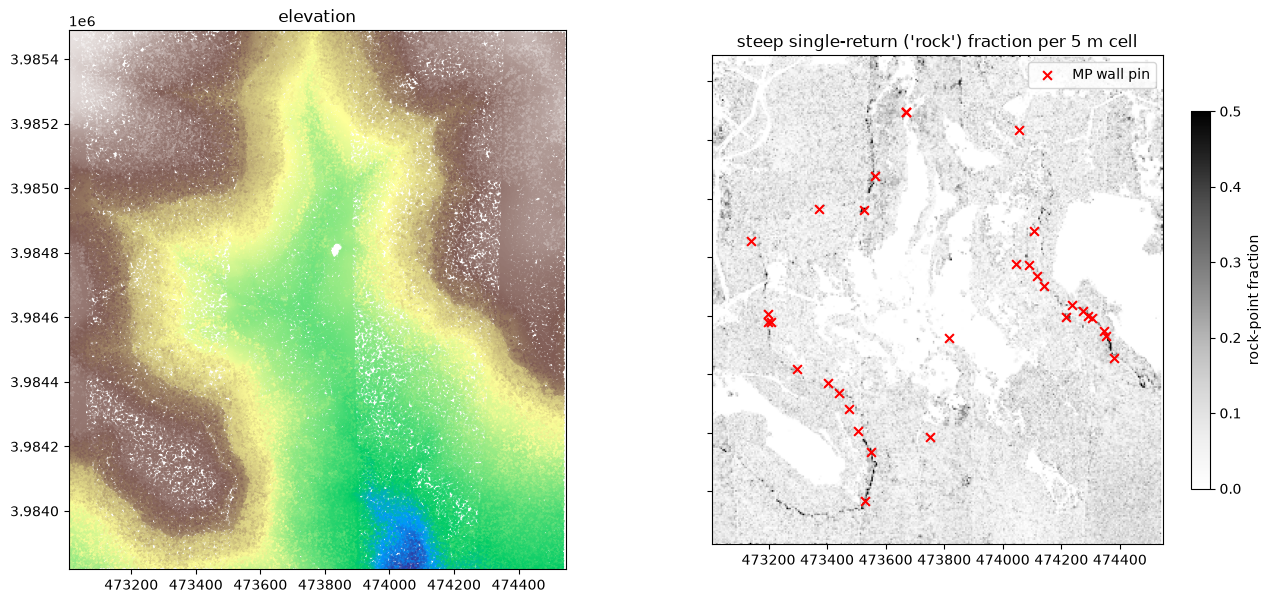

In [5]:
normals_path = cfg.region.cache_dir / f"normals_k{cfg.label.normal_k}_vox{cfg.label.normal_voxel_m}.npy"
if normals_path.exists():
    normals = np.load(normals_path)
else:
    normals = compute_normals(xyz, cfg.label.normal_k, cfg.label.normal_voxel_m)
    np.save(normals_path, normals)

pc = PointCloud.build(xyz, cfg.label, normals, cloud["number_of_returns"])
print(f"steep + single-return 'rock' points: {pc.steep.sum():,} ({pc.steep.mean():.1%})")

def rock_fraction_map(ax, cell_m=5.0):
    # share of each cell's points that are rock - a fraction, so the denser
    # flight-line overlap strips don't look darker just for having more points
    bins = [np.arange(xyz[:, i].min(), xyz[:, i].max() + cell_m, cell_m) for i in (0, 1)]
    total = np.histogram2d(xyz[:, 0], xyz[:, 1], bins)[0]
    rock = np.histogram2d(xyz[pc.steep, 0], xyz[pc.steep, 1], bins)[0]
    frac = np.where(total > 0, rock / np.maximum(total, 1), np.nan)
    im = ax.imshow(frac.T, origin="lower", extent=[bins[0][0], bins[0][-1], bins[1][0], bins[1][-1]],
                   cmap="Greys", vmin=0, vmax=0.5)
    plt.colorbar(im, ax=ax, shrink=0.7, label="rock-point fraction")
    ax.set(aspect="equal", title=f"steep single-return ('rock') fraction per {cell_m:g} m cell")


pins = lonlat_to_work(walls["lon"].to_numpy(), walls["lat"].to_numpy())
sub = np.random.default_rng(0).choice(len(xyz), 400_000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
axes[0].scatter(xyz[sub, 0], xyz[sub, 1], c=xyz[sub, 2], s=0.2, cmap="terrain")
axes[0].set(title="elevation", aspect="equal")
rock_fraction_map(axes[1])
axes[1].scatter(pins[:, 0], pins[:, 1], s=40, c="red", marker="x", label="MP wall pin")
axes[1].legend()
plt.show()

## 4. Weak labels: route cylinders, negatives, and what the LiDAR can actually see

For each wall pin we look ≤ 30 m away for vertical columns holding ≥ 8 rock points and place one 2.5 m cylinder per route there (≥ 3 m apart, nearest first). Each cylinder spans the cliff base (5th-percentile Z) to base + MP route length. A cylinder whose height range holds < 8 steep returns is **unseen by the LiDAR** and dropped.

Negatives: step 12 m / 20 m out from the face (talus) and back over the top (plateau), plus random terrain ≥ 40 m from every pin and route. A negative candidate that is itself mostly cliff could be good unlisted rock, so it is **ignored** rather than labelled 0.

In [6]:
samples, patches, positives_all = build_samples(pc, routes, cfg)
print("route cylinders:", positives_all["status"].value_counts().to_dict())
print("samples:", samples.groupby(["label", "source"]).size().to_dict())
print("negative candidates ignored as 'mostly cliff' (unknown):", samples.attrs["ignored_mostly_cliff"])

route cylinders: {'ok': 354, 'unseen_by_lidar': 75, 'default_pin': 3}
samples: {(0, 'random'): 300, (0, 'stepback_base'): 403, (0, 'stepback_top'): 390, (1, 'mp_route'): 354}
negative candidates ignored as 'mostly cliff' (unknown): 12


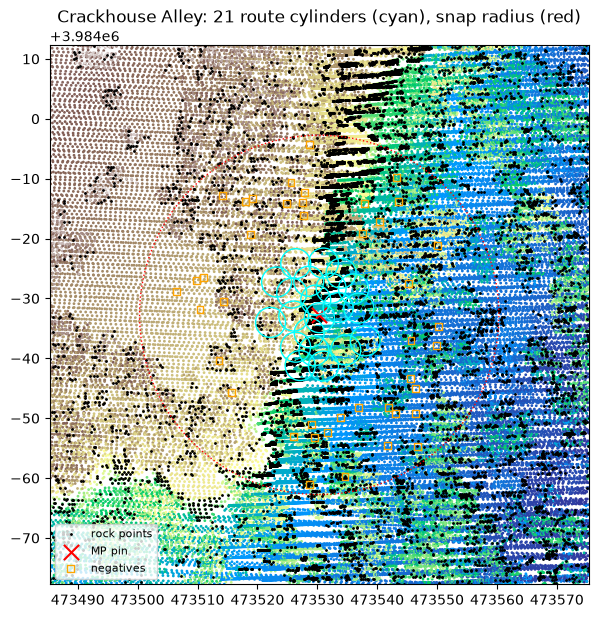

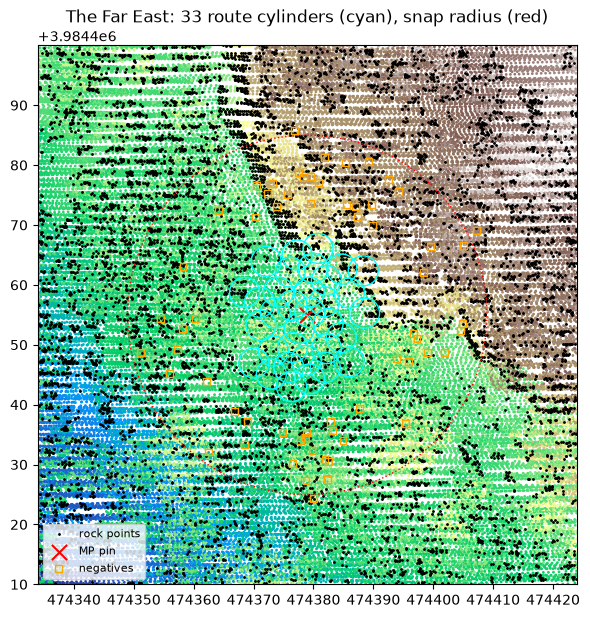

In [7]:
def show_wall(wall, half=45):
    ok = positives_all[(positives_all["wall"] == wall) & (positives_all["status"] == "ok")]
    pin = ok[["pin_x", "pin_y"]].iloc[0].to_numpy()
    idx = pc.column(pin, half * 1.5)
    idx = idx[np.all(np.abs(xyz[idx, :2] - pin) < half, axis=1)]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(xyz[idx, 0], xyz[idx, 1], c=xyz[idx, 2], s=1, cmap="terrain")
    r = idx[pc.steep[idx]]
    ax.scatter(xyz[r, 0], xyz[r, 1], s=1, c="k", label="rock points")
    ax.add_patch(plt.Circle(pin, cfg.label.snap_search_radius_m, fill=False, ls=":", color="red"))
    ax.scatter(*pin, marker="x", s=120, c="red", label="MP pin")
    for _, p in ok.iterrows():
        ax.add_patch(plt.Circle((p["x"], p["y"]), cfg.label.route_radius_m, fill=False, color="cyan"))
    neg = samples[(samples["label"] == 0) & (np.abs(samples["x"] - pin[0]) < half) & (np.abs(samples["y"] - pin[1]) < half)]
    ax.scatter(neg["x"], neg["y"], marker="s", s=25, facecolors="none", edgecolors="orange", label="negatives")
    ax.set(xlim=(pin[0] - half, pin[0] + half), ylim=(pin[1] - half, pin[1] + half), aspect="equal",
           title=f"{wall}: {len(ok)} route cylinders (cyan), snap radius (red)")
    ax.legend(loc="lower left", fontsize=8)
    plt.show()


show_wall("Crackhouse Alley")
show_wall("The Far East")

### Feasibility: can airborne LiDAR see a climbing route?

For each kept cylinder:

* **coverage** — fraction of 1 m height bins between base and top with at least one rock return (1.0 = the whole route was seen);
* **max_gap_m** — tallest run of empty bins (a roof hides what is under it);
* **lean_deg** — line fit of the rock points' outward offset vs. height: < 0 the wall lays back, ≈ 0 vertical, > 0 the top sticks out over the base (overhang).

Horseshoe Canyon is known for steep-to-overhanging sandstone. If the lean distribution sits at or below zero, the airborne sensor is mostly seeing the lip and the base, not the overhang itself — which is the core feasibility concern for a slab/face/overhang classifier.

       snap_dist_m  length_m  n_steep  coverage  max_gap_m  lean_deg
count       354.00    354.00   354.00    354.00     354.00    352.00
mean          8.49     16.06    28.34      0.47       5.63     -5.23
std           6.19      6.07    41.45      0.19       5.46     11.57
min           0.08      6.10     8.00      0.07       0.00    -36.22
25%           4.26     12.19     9.25      0.32       3.00    -12.07
50%           6.83     15.24    13.00      0.43       5.00     -6.22
75%           9.95     18.29    25.75      0.57       7.00      0.03
max          29.79     91.44   287.00      1.00      83.00     56.95


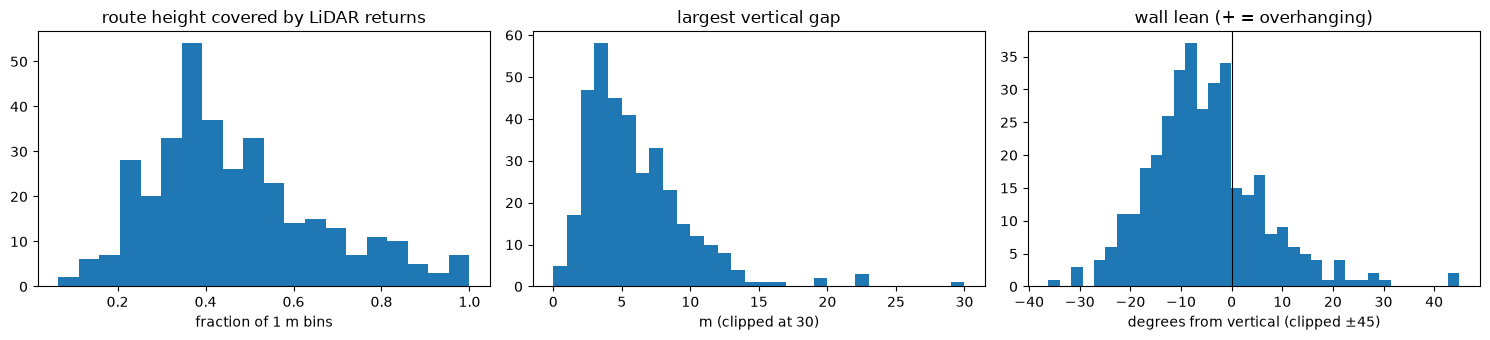

share of routes measured as overhanging (lean > 5 deg): 15.8%
share of routes with >= 80% height coverage: 8.5%


,routes,snap_m,coverage,gap_m,lean_deg
wall,,,,,
North Forty Routes,65,18.81,0.36,5.0,-7.07
The Far East,33,7.94,0.45,7.0,-1.05
Crackhouse Alley,21,6.69,0.55,6.0,-1.02
Walls Of Moria,21,11.26,0.31,5.0,-3.73
The Land Beyond Routes,20,6.32,0.70,2.0,-5.88
Confederate Cracks,20,6.11,0.77,2.5,-5.92
Kindergarten Boulder,19,7.16,0.60,3.0,-16.35
The Arcade,17,6.37,0.37,6.0,-4.01
Cliffs of Insanity,16,5.76,0.39,8.0,-9.03


In [8]:
ok = positives_all[positives_all["status"] == "ok"]
print(ok[["snap_dist_m", "length_m", "n_steep", "coverage", "max_gap_m", "lean_deg"]].describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(ok["coverage"], bins=20)
axes[0].set(title="route height covered by LiDAR returns", xlabel="fraction of 1 m bins")
axes[1].hist(ok["max_gap_m"].clip(upper=30), bins=30)
axes[1].set(title="largest vertical gap", xlabel="m (clipped at 30)")
axes[2].hist(ok["lean_deg"].dropna().clip(-45, 45), bins=36)
axes[2].axvline(0, color="k", lw=0.8)
axes[2].set(title="wall lean (+ = overhanging)", xlabel="degrees from vertical (clipped ±45)")
plt.tight_layout()
plt.show()
print(f"share of routes measured as overhanging (lean > 5 deg): {(ok['lean_deg'] > 5).mean():.1%}")
print(f"share of routes with >= 80% height coverage: {(ok['coverage'] >= 0.8).mean():.1%}")

(ok.groupby("wall")
   .agg(routes=("x", "size"), snap_m=("snap_dist_m", "median"), coverage=("coverage", "median"),
        gap_m=("max_gap_m", "median"), lean_deg=("lean_deg", "median"))
   .sort_values("routes", ascending=False).round(2))

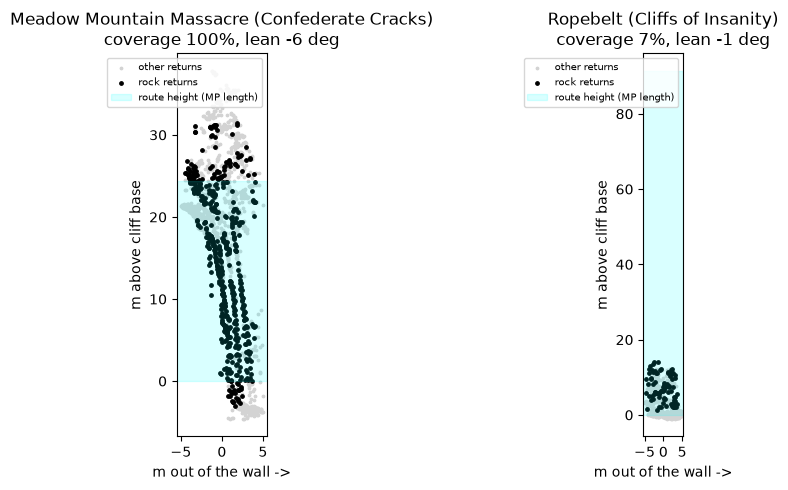

In [9]:
# side view of the best- and worst-covered routes: offset out of the wall vs height
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (_, p) in zip(axes, ok.sort_values("coverage").iloc[[-1, 0]].iterrows()):
    idx = pc.column((p["x"], p["y"]), cfg.patch.radius_m)
    out = np.array([p["out_dx"], p["out_dy"]])
    off = (xyz[idx, :2] - [p["x"], p["y"]]) @ out
    is_rock = pc.steep[idx]
    ax.scatter(off[~is_rock], xyz[idx, 2][~is_rock] - p["base_z"], s=3, c="lightgray", label="other returns")
    ax.scatter(off[is_rock], xyz[idx, 2][is_rock] - p["base_z"], s=6, c="k", label="rock returns")
    ax.axhspan(0, p["length_m"], color="cyan", alpha=0.15, label="route height (MP length)")
    ax.set(title=f"{p['route']} ({p['wall']})\ncoverage {p['coverage']:.0%}, lean {p['lean_deg']:.0f} deg",
           xlabel="m out of the wall ->", ylabel="m above cliff base", aspect="equal")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 5. Patches and the spatial split

Every sample's input is the **full vertical column** of points within 5 m of its centre (the 2.5 m cylinder is only used for labelling), resampled to 1024 points and normalised to the unit sphere exactly like ModelNet40. Whole walls are dealt to train / val / test so overlapping neighbouring cylinders never straddle splits; negatives follow their nearest wall.

In [10]:
samples = split_walls(samples, cfg.split)
save_samples(cfg.region.cache_dir / "samples", samples, patches)
split_summary(samples)

label,negatives,positives,n_walls,walls
split,,,,
train,633,212,18,"Cliffs of Insanity, Confederate Cracks, Goat C..."
val,220,71,6,"Magoo Rock, The Arcade, The Doomsday Wall, The..."
test,240,71,6,"Crackhouse Alley, Mexican Pillar, Nipple Stimu..."


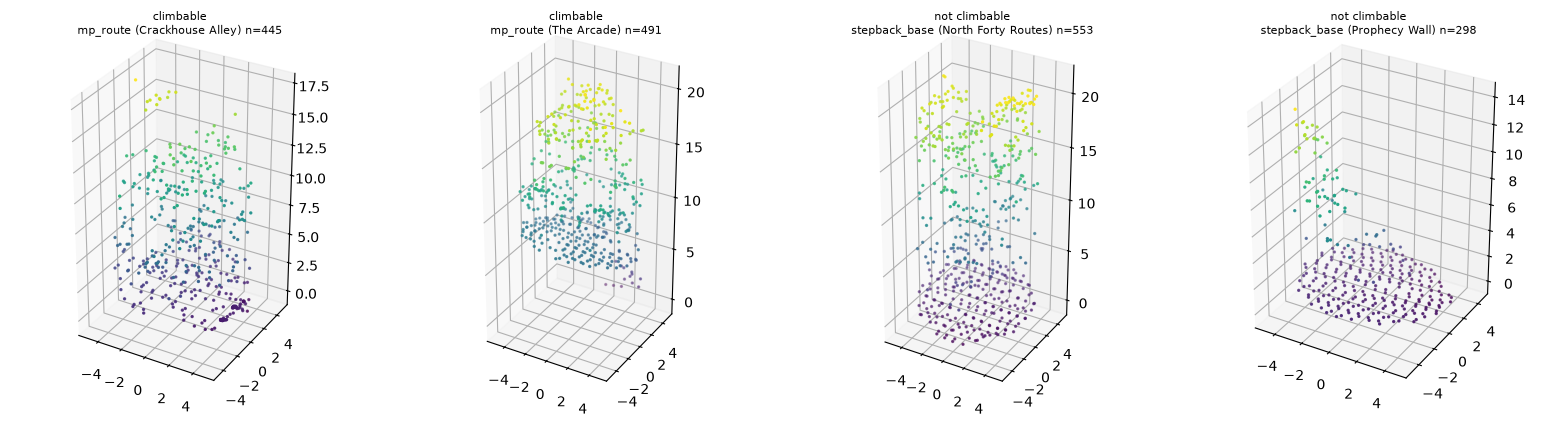

In [11]:
fig = plt.figure(figsize=(16, 4))
picks = pd.concat([samples[samples["label"] == 1].sample(2, random_state=1), samples[samples["label"] == 0].sample(2, random_state=1)])
for k, (i, row) in enumerate(picks.iterrows()):
    pts = patches[i]
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=pts[:, 2], s=2, cmap="viridis")
    ax.set_title(f"{'climbable' if row['label'] else 'not climbable'}\n{row['source']} ({row['wall']}) n={len(pts)}", fontsize=8)
    ax.set_box_aspect((1, 1, max(np.ptp(pts[:, 2]) / 10, 0.3)))
plt.tight_layout()
plt.show()

## 6. Pretrained PointNet++ (ModelNet40, xyz only)

Weights: `yanx27/Pointnet_Pointnet2_pytorch` → `log/classification/pointnet2_ssg_wo_normals` (92.5 % ModelNet40 instance accuracy). Everything but the 40-way `fc3` loads; `fc3` is replaced by a fresh 2-way layer. Three modes are trained on the same split:

* **scratch** — random init (baseline: does pretraining matter at all?)
* **head** — pretrained set-abstraction layers frozen, fc1–fc3 trained
* **finetune** — everything trained, backbone at 0.1× the head's LR

In [12]:
for mode in ("scratch", "head", "finetune"):
    model, report = build_model(mode)
    trainable, total = count_parameters(model)
    print(f"{mode:9s} trainable {trainable:>9,} / {total:,}", "" if report is None else f"| loaded {report['loaded']} tensors, fresh: {report['fresh']}")

scratch   trainable 1,465,922 / 1,465,922 
head      trainable   658,178 / 1,465,922 | loaded 77 tensors, fresh: ['fc3.bias', 'fc3.weight']
finetune  trainable 1,465,922 / 1,465,922 | loaded 77 tensors, fresh: ['fc3.bias', 'fc3.weight']


## 7. Fine-tune and compare on held-out walls

Loss is class-weighted cross-entropy (there are ~3 negatives per positive); the checkpoint with the best **validation balanced accuracy** is kept and then scored on the **test walls**, which no model has seen in any form. With `FAST_DEV_RUN` (no CUDA) this only runs a couple of epochs to prove the loop works — the numbers mean nothing until it is run on the GPU machine.

In [13]:
loaders = make_loaders(samples, patches, cfg.patch, batch_size=BATCH_SIZE, num_workers=0 if FAST_DEV_RUN else 4)
results, trainers = compare_modes(loaders, TrainConfig(run_name="hcr", epochs=EPOCHS))
results.pivot(index="mode", columns="split", values=["balanced_acc", "auroc", "precision", "recall", "f1"]).round(3)

22:49:56 run=hcr-scratch mode=scratch device=mps params 1465922/1465922 trainable


22:50:25 epoch   1  train_loss 0.6887  val_loss 1.9375  val_bal_acc 0.500  val_auroc 0.475  val_f1 0.392  28.5s  *


22:50:53 epoch   2  train_loss 0.6123  val_loss 0.6850  val_bal_acc 0.636  val_auroc 0.679  val_f1 0.463  27.8s  *


22:51:16 run=hcr-head mode=head device=mps params 658178/1465922 trainable


22:51:16 pretrained: {'checkpoint': 'modelnet40_ssg', 'loaded': 77, 'skipped': ['fc3.bias', 'fc3.weight'], 'fresh': ['fc3.bias', 'fc3.weight'], 'pretrain_epoch': 71, 'pretrain_instance_acc': 0.9253236245954691}


...

22:52:16 run=hcr-finetune mode=finetune device=mps params 1465922/1465922 trainable


22:52:16 pretrained: {'checkpoint': 'modelnet40_ssg', 'loaded': 77, 'skipped': ['fc3.bias', 'fc3.weight'], 'fresh': ['fc3.bias', 'fc3.weight'], 'pretrain_epoch': 71, 'pretrain_instance_acc': 0.9253236245954691}


22:52:45 epoch   1  train_loss 0.6681  val_loss 0.7026  val_bal_acc 0.644  val_auroc 0.684  val_f1 0.469  28.2s  *


22:53:13 epoch   2  train_loss 0.5773  val_loss 0.6262  val_bal_acc 0.656  val_auroc 0.699  val_f1 0.481  28.1s  *


balanced_acc         auroc        precision        recall            f1       
split            test    val   test    val      test    val   test    val   test    val
mode                                                                                   
finetune        0.666  0.659  0.694  0.697     0.377  0.433  0.648  0.549  0.477  0.484
head            0.655  0.623  0.698  0.693     0.413  0.435  0.535  0.423  0.466  0.429
scratch         0.641  0.615  0.646  0.678     0.320  0.331  0.761  0.662  0.450  0.441

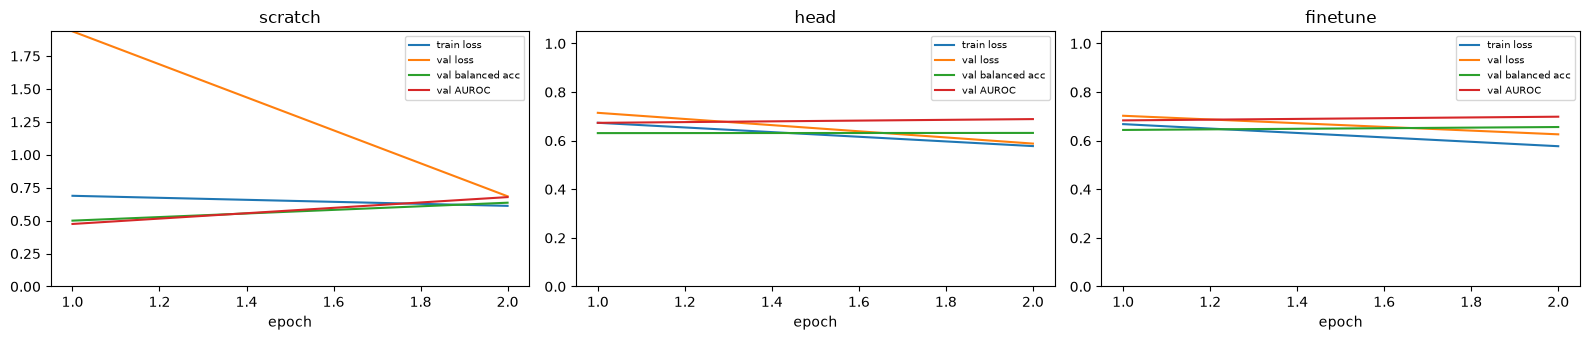

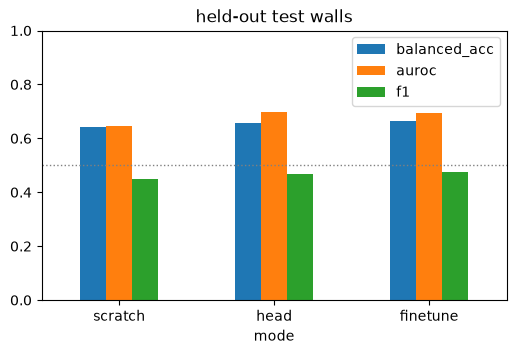

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, (mode, tr) in zip(axes, trainers.items()):
    h = pd.DataFrame(tr.history)
    ax.plot(h["epoch"], h["train_loss"], label="train loss")
    ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax.plot(h["epoch"], h["val_balanced_acc"], label="val balanced acc")
    ax.plot(h["epoch"], h["val_auroc"], label="val AUROC")
    ax.set(title=mode, xlabel="epoch", ylim=(0, max(1.05, h[["train_loss", "val_loss"]].values.max())))
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

test = results[results["split"] == "test"].set_index("mode")
test[["balanced_acc", "auroc", "f1"]].plot.bar(figsize=(6, 3.5), ylim=(0, 1), title="held-out test walls", rot=0)
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.show()

### Where are the test-set errors?

Per test sample: is the model failing on positives the LiDAR barely saw (low coverage), or on particular negative types?

In [15]:
# pick the mode on validation, never on test
best_mode = results[results["split"] == "val"].set_index("mode")["balanced_acc"].idxmax()
labels, probs, _ = trainers[best_mode].predict(loaders["test"])
test_rows = loaders["test"].dataset.rows.assign(prob=probs, correct=(probs >= 0.5) == labels.astype(bool))
print("best mode on validation:", best_mode)
print(test_rows.groupby(["label", "source"])["correct"].agg(["mean", "size"]).rename(columns={"mean": "accuracy"}).round(3))

pos_test = test_rows[test_rows["label"] == 1].merge(ok[["x", "y", "coverage", "lean_deg"]], on=["x", "y"], how="left")
pos_test["coverage_bin"] = pd.cut(pos_test["coverage"], [0, 0.3, 0.5, 0.7, 1.0])
print("\nrecall on test positives by LiDAR height coverage:")
print(pos_test.groupby("coverage_bin", observed=True)["correct"].agg(["mean", "size"]).rename(columns={"mean": "recall"}).round(3))

best mode on validation: finetune
                     accuracy  size
label source                       
0     random            0.810    58
      stepback_base     0.652    92
      stepback_top      0.656    90
1     mp_route          0.634    71

recall on test positives by LiDAR height coverage:
              recall  size
coverage_bin              
(0.0, 0.3]     0.500     8
(0.3, 0.5]     0.522    23
(0.5, 0.7]     0.625    24
(0.7, 1.0]     0.875    16


## 8. Probability map over the whole ranch

Slide the best model over a regular grid (same 5 m column input at every node). Bright cells far from any Mountain Project pin are either false positives or rock nobody has logged — the latter is the whole point of the tool.

grid:   0%|          | 0/11322 [00:00<?, ?it/s]

grid:   1%|          | 64/11322 [00:01<04:06, 45.69it/s]

grid:   1%|          | 128/11322 [00:02<03:41, 50.58it/s]

grid:   2%|▏         | 192/11322 [00:03<03:29, 53.13it/s]

grid:   2%|▏         | 256/11322 [00:04<03:11, 57.69it/s]

...

grid:  98%|█████████▊| 11074/11322 [03:08<00:04, 54.81it/s]

grid:  98%|█████████▊| 11138/11322 [03:09<00:03, 54.43it/s]

grid:  99%|█████████▉| 11202/11322 [03:10<00:02, 56.11it/s]

grid: 100%|█████████▉| 11266/11322 [03:11<00:00, 59.41it/s]

grid: 100%|██████████| 11322/11322 [03:11<00:00, 59.14it/s]

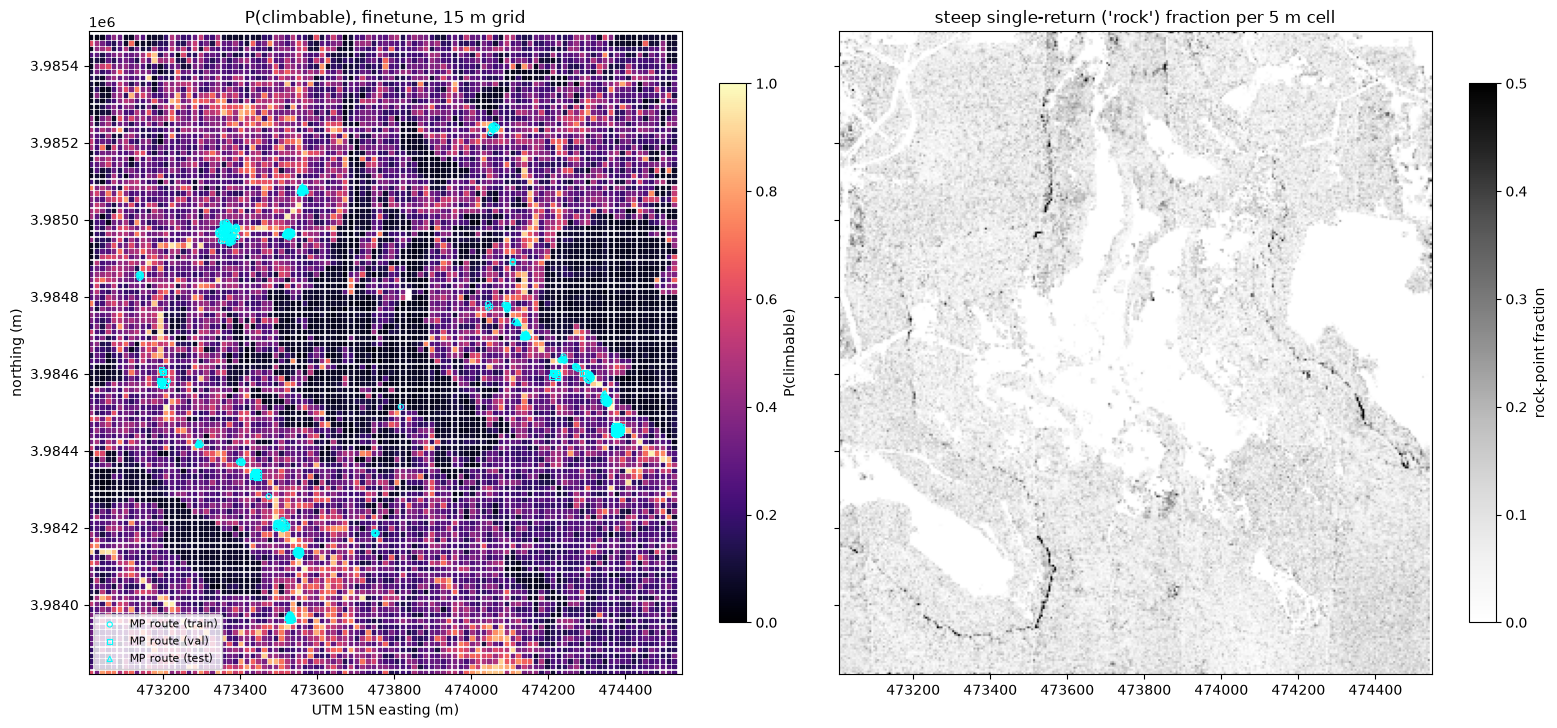

In [16]:
model = trainers[best_mode].model
grid = predict_grid(model, pc, cfg.patch, spacing_m=GRID_SPACING_M, batch_size=64)
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
plot_probability_map(grid, samples, ax=axes[0], title=f"P(climbable), {best_mode}, {GRID_SPACING_M:g} m grid")
rock_fraction_map(axes[1])
plt.tight_layout()
plt.show()
grid.to_csv(cfg.region.cache_dir / f"probability_grid_{best_mode}.csv", index=False)

## 9. Takeaways and next steps

* **Label quality is the bottleneck, not the network.** MP gives wall-level pins 5–20 m off the rock; the snapping heuristic and single-return filter are what make positives land on cliff at all. Per-route coordinates (or the OpenBeta dataset, which sometimes has them) would tighten this most.
* **Overhangs are largely invisible to nadir airborne LiDAR** — see the coverage / lean histograms in section 4. A 4-class slab/face/overhang head would need either terrestrial/drone scans or labels that do not come from geometry the sensor cannot see.
* **Pretraining:** compare *scratch* vs *head* vs *finetune* on the test walls above once trained on the GPU machine (`FAST_DEV_RUN = False`). With only ~20 walls in training, the test split holds a handful of walls, so repeat over several `SplitConfig.seed` values before drawing conclusions.
* **Harder negatives** (choss, road cuts, dirt banks) from geology maps and a second crag with a different rock type would be the next step toward a model that generalises beyond this canyon.